<a href="https://colab.research.google.com/github/bulut19/stockout-aware-forecasting/blob/main/stream1_daily_vs_hourly.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stream 1 Daily versus hourly analysis and demand checks

This notebook completes only Stream 1. It measures how much missed demand a daily zero-sales rule fails to detect, reports the result overall and by category and stockout level, shows one product-day, checks a day-adjusted-average alternative, and compares LSTM, transformer, and dilated 1-D CNN gap fillers using last week's same-hour sales as context.

In [1]:
from pathlib import Path
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
sns.set_theme(style='whitegrid')
print('Device:', DEVICE)

Device: cuda


## Load the established project files

The notebook uses only FreshRetailNet-derived files created by the shared setup and missed-demand notebooks. It does not introduce another dataset.

In [2]:
from google.colab import drive
drive.mount('/content/drive')
PROC_DIR = Path('/content/drive/MyDrive/MIS 382 Deep Learning and ML/Final Project/Stockout Project Data/processed')
required = ['daily_model.parquet', 'daily_demand_v1.parquet', 'hourly_demand_v1.parquet', 'sample_ids.csv']
missing = [name for name in required if not (PROC_DIR / name).exists()]
if missing:
    raise FileNotFoundError(f'Missing established Stream 1 inputs: {missing}')

daily_model = pd.read_parquet(PROC_DIR / 'daily_model.parquet')
daily = pd.read_parquet(PROC_DIR / 'daily_demand_v1.parquet')
hourly = pd.read_parquet(PROC_DIR / 'hourly_demand_v1.parquet')
sample = pd.read_csv(PROC_DIR / 'sample_ids.csv')

for frame in (daily_model, daily, hourly):
    if 'dt' in frame.columns:
        frame['dt'] = pd.to_datetime(frame['dt'])

print('daily_model:', daily_model.shape, list(daily_model.columns))
print('daily_demand_v1:', daily.shape, list(daily.columns))
print('hourly_demand_v1:', hourly.shape, list(hourly.columns))
print('sample_ids:', sample.shape, list(sample.columns))

Mounted at /content/drive
daily_model: (4850000, 25) ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'stock_hour6_22_cnt', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level', 'split', 'series_id', 'discount_missing', 'any_stockout', 'zero_sales_day', 'day_of_week', 'set', 'in_sample']
daily_demand_v1: (194000, 8) ['series_id', 'dt', 'sales', 'demand', 'lost_demand', 'oos_hours', 'set', 'zero_sales_day']
hourly_demand_v1: (3104000, 9) ['series_id', 'dt', 'hour', 'split', 'sales', 'out_of_stock', 'demand_est', 'demand', 'lost_demand']
sample_ids: (2000, 4) ['series_id', 'category', 'stockout_rate', 'stockout_band']


## Daily zero-sales estimate
The daily view flags zero-sales stockout days and estimates lost demand from normal daily sales on fully stocked training days. The headline is the share of hourly estimated lost demand occurring on days with positive recorded sales, which daily zero-sales detection cannot see. The daily estimate's numerical shortfall is reported separately, because it also includes differences between the daily and hourly estimators.

In [3]:
# Add category and the frozen stockout bands from the shared setup.
info = daily_model[['series_id', 'first_category_id']].drop_duplicates('series_id')
daily = daily.merge(info, on='series_id', how='left').merge(
    sample[['series_id', 'stockout_band']], on='series_id', how='left'
)

# Normal daily sales are estimated only from fully in-stock training days.
normal_source = daily[(daily['set'] == 'train') & (daily['oos_hours'] == 0)]
normal_by_product = normal_source.groupby('series_id')['sales'].mean()
category_fallback = normal_source.groupby(
    normal_source['series_id'].map(info.set_index('series_id')['first_category_id'])
)['sales'].mean()
daily['normal_daily_sales'] = daily['series_id'].map(normal_by_product)
daily['normal_daily_sales'] = daily['normal_daily_sales'].fillna(
    daily['first_category_id'].map(category_fallback)
).fillna(normal_source['sales'].mean())

# A daily system flags only a zero-sales day; partial-day stockouts remain invisible.
daily['daily_stockout_flag'] = ((daily['sales'] == 0) & (daily['oos_hours'] > 0)).astype('int8')
daily['daily_missed_est'] = np.where(
    daily['daily_stockout_flag'].eq(1),
    np.maximum(daily['normal_daily_sales'] - daily['sales'], 0),
    0.0
)
daily['hourly_missed_est'] = daily['lost_demand'].clip(lower=0)

daily[['daily_stockout_flag', 'daily_missed_est', 'hourly_missed_est']].describe().round(3)

,daily_stockout_flag,daily_missed_est,hourly_missed_est
count,194000.000,194000.000,194000.000
mean,0.038,0.043,0.199
std,0.191,0.459,0.672
min,0.000,0.000,0.000
25%,0.000,0.000,0.000
50%,0.000,0.000,0.000
75%,0.000,0.000,0.207
max,1.000,25.133,22.790


In [4]:
# Use the same hourly-demand denominator for the main headline and sensitivity.
def missed_summary(frame, missed_col='hourly_missed_est'):
    total = frame[missed_col].sum()
    invisible = frame.loc[frame['sales'].gt(0), missed_col].sum()
    daily_total = frame['daily_missed_est'].sum()
    return pd.Series({
        'product_days': len(frame),
        'hourly_missed_demand': total,
        'daily_missed_demand': daily_total,
        'daily_share_captured': 1 - invisible / total if total > 0 else np.nan,
        'share_missed_by_daily': invisible / total if total > 0 else np.nan,
        'daily_estimate_shortfall': 1 - daily_total / total if total > 0 else np.nan
    })
overall = missed_summary(daily).to_frame('overall').T
by_category = daily.groupby('first_category_id', dropna=False).apply(missed_summary, include_groups=False).sort_values('hourly_missed_demand', ascending=False)
by_band = daily.groupby('stockout_band', observed=True).apply(missed_summary, include_groups=False)
headline = overall.loc['overall', 'share_missed_by_daily']
print(f'HEADLINE: Daily data misses {headline:.1%} of hourly estimated missed demand because those days still show sales.')
print('Daily-estimate shortfall is a separate quantity: it also reflects disagreement between the two estimators.')
display(overall.round(4)); display(by_band.round(4)); display(by_category.round(4))
display(daily.groupby('set').apply(missed_summary, include_groups=False).round(4))
per_product_headline = daily.groupby('series_id').apply(missed_summary, include_groups=False)
print('Across-product headline distribution (products with estimated lost demand):')
display(per_product_headline['share_missed_by_daily'].dropna().describe(percentiles=[.1,.25,.5,.75,.9]).round(4))

HEADLINE: Daily data misses 80.9% of hourly estimated missed demand because those days still show sales.
Daily-estimate shortfall is a separate quantity: it also reflects disagreement between the two estimators.


,product_days,hourly_missed_demand,daily_missed_demand,daily_share_captured,share_missed_by_daily,daily_estimate_shortfall
overall,194000.0,38581.0375,8381.297,0.1914,0.8086,0.7828


,product_days,hourly_missed_demand,daily_missed_demand,daily_share_captured,share_missed_by_daily,daily_estimate_shortfall
stockout_band,,,,,,
high,60043.0,21752.2705,4416.7303,0.1742,0.8258,0.7970
low,69258.0,7195.4075,2150.7304,0.2655,0.7345,0.7011
medium,64699.0,9633.3595,1813.8363,0.1747,0.8253,0.8117


,product_days,hourly_missed_demand,daily_missed_demand,daily_share_captured,share_missed_by_daily,daily_estimate_shortfall
first_category_id,,,,,,
4,42292.0,9765.8377,2130.8223,0.2088,0.7912,0.7818
21,10961.0,6404.5495,1560.2284,0.1616,0.8384,0.7564
20,21437.0,4838.8762,1364.6237,0.2756,0.7244,0.7180
16,27936.0,3375.9203,65.1817,0.0170,0.9830,0.9807
29,13580.0,3290.1829,218.4209,0.0614,0.9386,0.9336
28,7760.0,2923.3756,1031.4252,0.3213,0.6787,0.6472
10,11058.0,1915.7516,933.0223,0.4353,0.5647,0.5130
8,11155.0,1121.7195,185.9270,0.1618,0.8382,0.8342
5,6402.0,917.0862,363.6292,0.3134,0.6866,0.6035


,product_days,hourly_missed_demand,daily_missed_demand,daily_share_captured,share_missed_by_daily,daily_estimate_shortfall
set,,,,,,
test,14000.0,2325.5508,525.8631,0.2179,0.7821,0.7739
train,152000.0,31362.7348,7031.2509,0.1935,0.8065,0.7758
valid,28000.0,4892.7519,824.1830,0.1650,0.8350,0.8316


Across-product headline distribution (products with estimated lost demand):


,share_missed_by_daily
count,2000.0000
mean,0.8396
std,0.2059
min,0.0769
10%,0.5091
25%,0.7529
50%,0.9273
75%,1.0000
90%,1.0000
max,1.0000


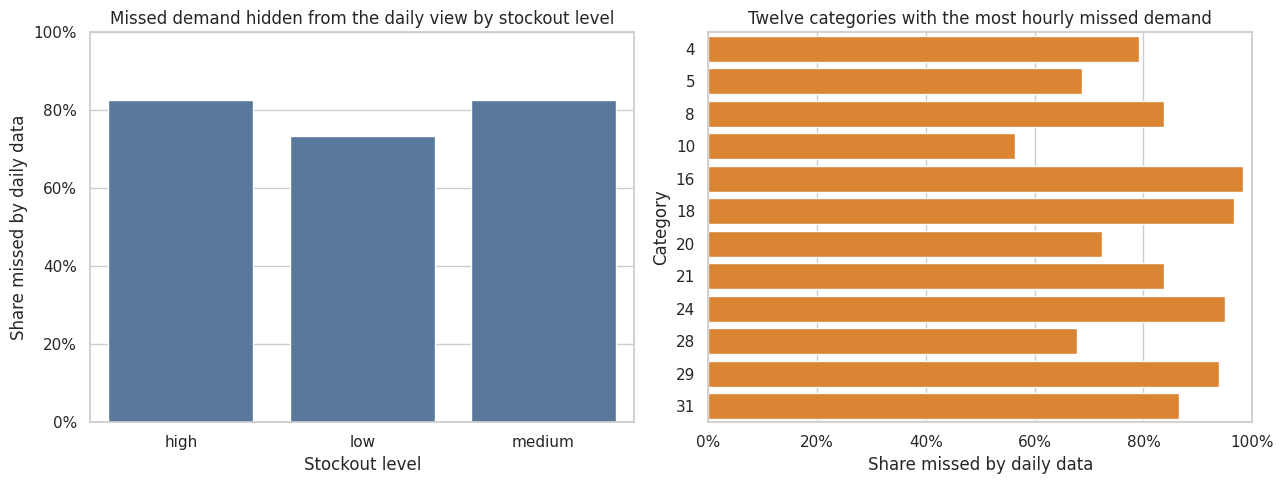

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
band_plot = by_band.reset_index()
sns.barplot(data=band_plot, x='stockout_band', y='share_missed_by_daily', color='#4C78A8', ax=axes[0])
axes[0].set(title='Missed demand hidden from the daily view by stockout level', xlabel='Stockout level', ylabel='Share missed by daily data', ylim=(0, 1))
axes[0].yaxis.set_major_formatter(lambda x, pos: f'{x:.0%}')
cat_plot = by_category.head(12).sort_values('share_missed_by_daily').reset_index()
sns.barplot(data=cat_plot, y='first_category_id', x='share_missed_by_daily', color='#F58518', orient='h', ax=axes[1])
axes[1].set(title='Twelve categories with the most hourly missed demand', xlabel='Share missed by daily data', ylabel='Category', xlim=(0, 1))
axes[1].xaxis.set_major_formatter(lambda x, pos: f'{x:.0%}')
plt.tight_layout()
plt.show()

## Example product-day

The example is the partial-stockout product-day with the most corrected missed demand. Selecting a partial day makes the daily method's blind spot visible: the day still has sales even though demand is lost during empty hours.

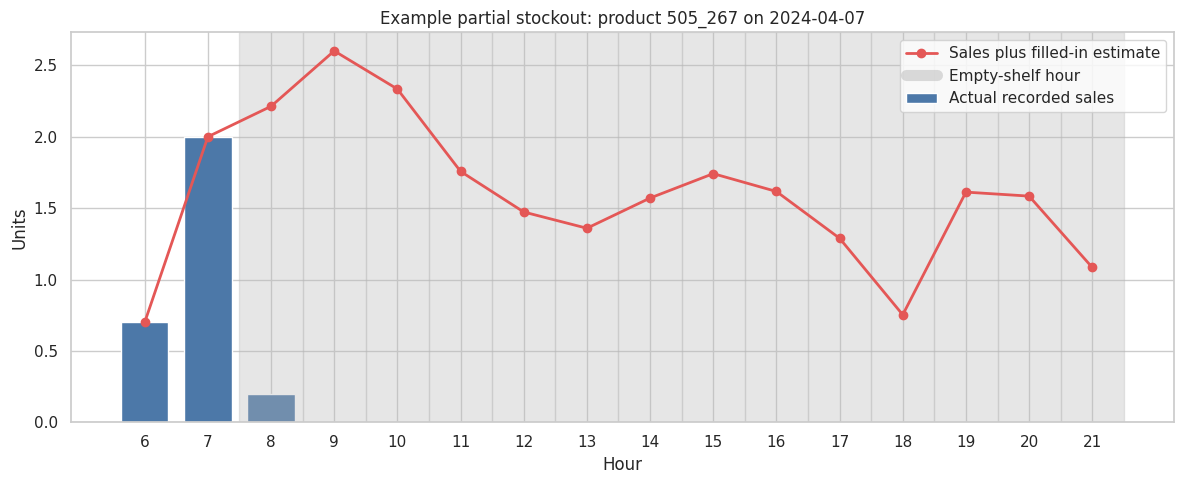

In [6]:
example_key = (daily[(daily['oos_hours'] > 0) & (daily['sales'] > 0)]
               .sort_values('hourly_missed_est', ascending=False)
               .iloc[0][['series_id', 'dt']])
example = hourly[(hourly['series_id'] == example_key['series_id']) &
                 (hourly['dt'] == example_key['dt'])].sort_values('hour')

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(example['hour'], example['sales'], width=0.75, color='#4C78A8', label='Actual recorded sales')
ax.plot(example['hour'], example['demand'], color='#E45756', marker='o', linewidth=2, label='Sales plus filled-in estimate')
for hour in example.loc[example['out_of_stock'].eq(1), 'hour']:
    ax.axvspan(hour - 0.5, hour + 0.5, color='#B9B9B9', alpha=0.35)
ax.plot([], [], color='#B9B9B9', linewidth=8, alpha=0.5, label='Empty-shelf hour')
ax.set(xticks=example['hour'], xlabel='Hour', ylabel='Units',
       title=f"Example partial stockout: product {example_key['series_id']} on {example_key['dt'].date()}")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

## Sensitivity to the day-adjusted average
Replace the existing LightGBM plus LSTM estimate with the team's day-adjusted average: a product-hour weekday/weekend profile from in-stock training hours, scaled by visible sales that day. Both headline calculations use the same definition: estimated lost demand on positive-sales days divided by all estimated lost demand. These are descriptive estimates, not observed demand during real stockouts.

In [7]:
# The historical profile matches the team's weekday/weekend day-adjusted baseline.
h = hourly.sort_values(['series_id', 'dt', 'hour']).copy()
h = h.merge(daily[['series_id', 'dt', 'set']], on=['series_id','dt'], validate='many_to_one')
h['weekend'] = h['dt'].dt.dayofweek.ge(5).astype('int8')
profile_source = h[h['set'].eq('train') & h['out_of_stock'].eq(0)]
profile_keys = ['series_id','hour','weekend']
profile = profile_source.groupby(profile_keys)['sales'].mean().rename('normal_hour_sales')
h = h.join(profile, on=profile_keys)
fallback = profile_source.groupby('hour')['sales'].mean()
h['normal_hour_sales'] = h['normal_hour_sales'].fillna(h['hour'].map(fallback)).fillna(0)
visible = h['out_of_stock'].eq(0)
keys = [h['series_id'],h['dt']]
visible_sales = h['sales'].where(visible,0).groupby(keys).transform('sum')
visible_base = h['normal_hour_sales'].where(visible,0).groupby(keys).transform('sum')
h['day_factor'] = ((visible_sales + 0.4)/(visible_base + 0.4)).clip(0.2,5)
h['dayadj_demand'] = np.where(visible, h['sales'], np.maximum(h['sales'], h['normal_hour_sales']*h['day_factor']))
h['dayadj_lost'] = h['dayadj_demand'] - h['sales']
dayadj = h.groupby(['series_id','dt'])['dayadj_lost'].sum().rename('dayadj_missed_est').reset_index()
sensitivity = daily.merge(dayadj, on=['series_id','dt'], validate='one_to_one')
rows=[]
for method,col in [('LightGBM + LSTM average','hourly_missed_est'),('Day-adjusted average','dayadj_missed_est')]:
    result=missed_summary(sensitivity,col)
    rows.append({'method':method, 'total_missed_demand':result['hourly_missed_demand'], 'share_missed_by_daily':result['share_missed_by_daily']})
sens_table=pd.DataFrame(rows)
sens_table['change_from_v1_percentage_points']=100*(sens_table['share_missed_by_daily']-headline)
assert np.isclose(sens_table.iloc[0]['share_missed_by_daily'],headline)
display(sens_table.round(4))
print(f'Day-adjusted headline change: {sens_table.iloc[1]["change_from_v1_percentage_points"]:+.2f} percentage points.')
print('All-period headlines describe v1 corrected demand; they do not evaluate unknown real stockout demand.')

,method,total_missed_demand,share_missed_by_daily,change_from_v1_percentage_points
0,LightGBM + LSTM average,38581.0375,0.8086,0.0000
1,Day-adjusted average,46287.0435,0.8077,-0.0987


Day-adjusted headline change: -0.10 percentage points.
All-period headlines describe v1 corrected demand; they do not evaluate unknown real stockout demand.


## Gap-filling model sensitivity
Compare LSTM, transformer, and dilated 1-D CNN under MAE, MSE, and Poisson losses using identical masks and initial weights. Inputs are visible sales, a visibility indicator, a historical product-hour profile, and last week's same-hour sales. Sales are scaled quantities.

Training ends June 11; validation is June 12-25; final testing is June 26-July 2. Profiles for evaluation are fitted on training observations only; training profiles use earlier observations. Last-week stockout sales are treated as censored and replaced by the historical profile. Fully stocked days receive 2-6 hour masks, with start probabilities learned only from training stockouts. Validation selects checkpoints; test data is scored after fitting.

Primary WAPE and MAE score individual hidden hours, consistent with the project plan. Gap-total WAPE is shown separately. This is retrospective demand recovery, so visible hours later on the same day are allowed; it is not a seven-day-ahead forecast. Simulated gaps on fully stocked days are easier than real stockouts, whose true demand is unknown. The prior random-split results are superseded.

In [8]:
# Frozen calendar splits match setup and the forecasting streams.
assert daily.loc[daily['set'].eq('train'),'dt'].max() == pd.Timestamp('2024-06-11')
assert daily.loc[daily['set'].eq('valid'),'dt'].min() == pd.Timestamp('2024-06-12')
assert daily.loc[daily['set'].eq('test'),'dt'].min() == pd.Timestamp('2024-06-26')
seq = h[['series_id','dt','hour','sales','out_of_stock','normal_hour_sales','set','weekend']].copy()
# Training features use earlier dates only; validation/test profiles use training data only.
known = seq['set'].eq('train') & seq['out_of_stock'].eq(0)
gkeys = [seq[k] for k in ['series_id','hour','weekend']]
prior_sum = seq['sales'].where(known,0).groupby(gkeys).cumsum() - seq['sales'].where(known,0)
prior_n = known.astype(int).groupby(gkeys).cumsum() - known.astype(int)
causal_profile = prior_sum / prior_n.replace(0,np.nan)
seq.loc[seq['set'].eq('train'),'normal_hour_sales'] = causal_profile.loc[seq['set'].eq('train')].fillna(0)
lag = seq[['series_id','dt','hour','sales','out_of_stock']].copy()
lag['dt'] += pd.Timedelta(days=7)
lag['lag7_sales'] = lag['sales'].where(lag['out_of_stock'].eq(0))
seq = seq.merge(lag[['series_id','dt','hour','lag7_sales']],on=['series_id','dt','hour'],how='left',validate='one_to_one')
seq['lag7_sales'] = seq['lag7_sales'].fillna(seq['normal_hour_sales'])
eligible = seq.groupby(['series_id','dt','set']).agg(hours=('hour','size'),oos=('out_of_stock','sum')).query('hours == 16 and oos == 0').reset_index()
# Require a week of history; cap only training rows, never held-out evaluation rows.
eligible = eligible[eligible['dt'] >= hourly['dt'].min()+pd.Timedelta(days=7)]
tr = eligible[eligible['set'].eq('train')]
tr = tr.sample(n=min(30000,len(tr)),random_state=SEED)
days = pd.concat([tr,eligible[eligible['set'].isin(['valid','test'])]]).sort_values(['series_id','dt']).reset_index(drop=True)
seq = seq.merge(days[['series_id','dt']],on=['series_id','dt'],how='inner',validate='many_to_one').sort_values(['series_id','dt','hour'])
assert len(seq)==16*len(days)
assert not days.duplicated(['series_id','dt']).any()
sales_seq=seq['sales'].to_numpy('float32').reshape(-1,16)
profile_seq=seq['normal_hour_sales'].to_numpy('float32').reshape(-1,16)
lag7_seq=seq['lag7_sales'].to_numpy('float32').reshape(-1,16)
# Derive block-start probabilities only from actual training stockout starts.
train_hours=h[h['set'].eq('train')].copy()
prev=train_hours.groupby(['series_id','dt'])['out_of_stock'].shift(1,fill_value=0)
start_counts=train_hours.loc[train_hours['out_of_stock'].eq(1)&prev.eq(0),'hour'].value_counts().reindex(range(6,22),fill_value=0).to_numpy()
start_probs=start_counts/start_counts.sum()
rng=np.random.default_rng(SEED)
mask_seq=np.zeros_like(sales_seq)
for i in range(len(days)):
    length=int(rng.integers(2,7))
    probs=start_probs[:17-length]; probs=probs/probs.sum()
    start=int(rng.choice(np.arange(17-length),p=probs))
    mask_seq[i,start:start+length]=1
visible_seq=1-mask_seq
x_seq=np.stack([sales_seq*visible_seq,visible_seq,profile_seq,lag7_seq],axis=-1)
y_seq=sales_seq[...,None]; m_seq=mask_seq[...,None]
indices={s:np.flatnonzero(days['set'].eq(s)) for s in ['train','valid','test']}
loaders={}
for s,idx in indices.items():
    ds=TensorDataset(torch.tensor(x_seq[idx]),torch.tensor(y_seq[idx]),torch.tensor(m_seq[idx]))
    loaders[s]=DataLoader(ds,batch_size=256 if s=='train' else 512,shuffle=s=='train',generator=torch.Generator().manual_seed(SEED))
train_loader,valid_loader,test_loader=(loaders[s] for s in ['train','valid','test'])
assert days.loc[indices['train'],'dt'].max()<days.loc[indices['valid'],'dt'].min()
assert days.loc[indices['valid'],'dt'].max()<days.loc[indices['test'],'dt'].min()
print('Fully stocked recovery days by frozen split:')
display(days.groupby('set')['dt'].agg(['min','max','size']))
print('Identical hidden blocks and inputs are used by every model/loss.')

Fully stocked recovery days by frozen split:


,min,max,size
set,,,
test,2024-06-26,2024-07-02,8285
train,2024-04-04,2024-06-11,30000
valid,2024-06-12,2024-06-25,15821


Identical hidden blocks and inputs are used by every model/loss.


In [9]:
class LSTMGapFiller(nn.Module):
    def __init__(self, n_in=4, hidden=48):
        super().__init__()
        self.net = nn.LSTM(n_in, hidden, num_layers=2, dropout=0.1, bidirectional=True, batch_first=True)
        self.out = nn.Linear(hidden * 2, 1)
    def forward(self, x):
        z, _ = self.net(x)
        return torch.nn.functional.softplus(self.out(z))
class TransformerGapFiller(nn.Module):
    def __init__(self, n_in=4, d_model=64):
        super().__init__()
        self.project = nn.Linear(n_in, d_model)
        self.position = nn.Parameter(torch.zeros(1, 16, d_model))
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=2)
        self.out = nn.Linear(d_model, 1)
    def forward(self, x):
        z = self.encoder(self.project(x) + self.position)
        return torch.nn.functional.softplus(self.out(z))
class DilatedCNNGapFiller(nn.Module):
    def __init__(self, n_in=4, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_in, hidden, 3, padding=1), nn.ReLU(),
            nn.Conv1d(hidden, hidden, 3, padding=2, dilation=2), nn.ReLU(),
            nn.Conv1d(hidden, hidden, 3, padding=4, dilation=4), nn.ReLU(),
            nn.Conv1d(hidden, 1, 1)
        )
    def forward(self, x):
        z = self.net(x.transpose(1, 2)).transpose(1, 2)
        return torch.nn.functional.softplus(z)
# MSE targets the conditional mean, while Poisson loss is designed for nonnegative count demand.
def masked_loss(pred, target, mask, loss_name):
    if loss_name == 'MSE':
        point_loss = (pred - target).pow(2)
    elif loss_name == 'Poisson':
        point_loss = pred - target * torch.log(pred.clamp_min(1e-8))
    elif loss_name == 'MAE':
        point_loss = (pred - target).abs()
    else:
        raise ValueError(f'Unsupported loss: {loss_name}')
    return (point_loss * mask).sum() / mask.sum().clamp_min(1)
def masked_mae(pred, target, mask):
    return ((pred - target).abs() * mask).sum() / mask.sum().clamp_min(1)
# Select checkpoints on validation objective; test data is never used during training.
def fit_model(model, loss_name, epochs=6):
    model=model.to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4)
    best_score,best_state=float('inf'),None
    for epoch in range(epochs):
        model.train()
        for xb,yb,mb in train_loader:
            xb,yb,mb=xb.to(DEVICE),yb.to(DEVICE),mb.to(DEVICE)
            optimizer.zero_grad()
            loss=masked_loss(model(xb),yb,mb,loss_name)
            loss.backward(); optimizer.step()
        model.eval(); total,count=0.0,0.0
        with torch.no_grad():
            for xb,yb,mb in valid_loader:
                xb,yb,mb=xb.to(DEVICE),yb.to(DEVICE),mb.to(DEVICE)
                n=mb.sum().item()
                total+=masked_loss(model(xb),yb,mb,loss_name).item()*n
                count+=n
        score=total/count
        if score<best_score:
            best_score,best_state=score,copy.deepcopy(model.state_dict())
        print(f'Epoch {epoch+1}: validation {loss_name}={score:.5f}')
    model.load_state_dict(best_state)
    return model


In [10]:
# Same initial weights, training order, masks and budget isolate the loss change.
model_factories={'LSTM':LSTMGapFiller,'Transformer':TransformerGapFiller,'Dilated 1-D CNN':DilatedCNNGapFiller}
trained={}
for model_name,factory in model_factories.items():
    for loss_name in ['MAE','MSE','Poisson']:
        torch.manual_seed(SEED)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
        train_loader.generator.manual_seed(SEED)
        print(f'\nTraining {model_name} with {loss_name}')
        trained[(model_name,loss_name)]=fit_model(factory(),loss_name)
print('Training complete. Checkpoints were selected using validation data only.')


Training LSTM with MAE
Epoch 1: validation MAE=0.06756
Epoch 2: validation MAE=0.06725
Epoch 3: validation MAE=0.06713
Epoch 4: validation MAE=0.06706
Epoch 5: validation MAE=0.06703
Epoch 6: validation MAE=0.06700

Training LSTM with MSE
Epoch 1: validation MSE=0.02388
Epoch 2: validation MSE=0.02250
Epoch 3: validation MSE=0.01657
Epoch 4: validation MSE=0.01422
Epoch 5: validation MSE=0.01303
Epoch 6: validation MSE=0.01225

Training LSTM with Poisson
Epoch 1: validation Poisson=0.24627
Epoch 2: validation Poisson=0.22356
Epoch 3: validation Poisson=0.22051
Epoch 4: validation Poisson=0.21989
Epoch 5: validation Poisson=0.21844
Epoch 6: validation Poisson=0.21784

Training Transformer with MAE
Epoch 1: validation MAE=0.06188
Epoch 2: validation MAE=0.05874
Epoch 3: validation MAE=0.05706
Epoch 4: validation MAE=0.05832
Epoch 5: validation MAE=0.05627
Epoch 6: validation MAE=0.05662

Training Transformer with MSE
Epoch 1: validation MSE=0.01201
Epoch 2: validation MSE=0.01213
Epoch 

Validation results (used to compare model/loss configurations):


,model,loss,set,hidden_hour_WAPE,hidden_hour_MAE,bias,gap_total_WAPE,mean_prediction,mean_actual,near_zero_share,hidden_hours
6,Transformer,MAE,valid,0.8408,0.0563,-0.6368,0.7259,0.0243,0.0669,0.8117,63267
8,Transformer,MSE,valid,0.9841,0.0659,-0.1482,0.5751,0.0570,0.0669,0.0000,63267
16,Dilated 1-D CNN,Poisson,valid,0.9937,0.0665,-0.0713,0.5705,0.0622,0.0669,0.0000,63267
14,Dilated 1-D CNN,MSE,valid,0.9991,0.0669,-0.0917,0.5746,0.0608,0.0669,0.0000,63267
12,Dilated 1-D CNN,MAE,valid,1.0000,0.0669,-1.0000,1.0000,0.0000,0.0669,1.0000,63267
0,LSTM,MAE,valid,1.0012,0.0670,-0.9968,0.9985,0.0002,0.0669,1.0000,63267
2,LSTM,MSE,valid,1.0066,0.0674,-0.1729,0.5950,0.0554,0.0669,0.0000,63267
10,Transformer,Poisson,valid,1.0190,0.0682,0.0057,0.5804,0.0673,0.0669,0.0000,63267
4,LSTM,Poisson,valid,1.0401,0.0696,0.0037,0.6000,0.0672,0.0669,0.0000,63267


Final test results (Jun 26-Jul 2; no tuning on this week):


,model,loss,set,hidden_hour_WAPE,hidden_hour_MAE,bias,gap_total_WAPE,mean_prediction,mean_actual,near_zero_share,hidden_hours
7,Transformer,MAE,test,0.8014,0.0608,-0.6061,0.6886,0.0299,0.0759,0.7979,33189
9,Transformer,MSE,test,0.9181,0.0697,-0.1608,0.5403,0.0637,0.0759,0.0000,33189
17,Dilated 1-D CNN,Poisson,test,0.9216,0.0700,-0.1015,0.5366,0.0682,0.0759,0.0000,33189
15,Dilated 1-D CNN,MSE,test,0.9279,0.0704,-0.1122,0.5399,0.0674,0.0759,0.0000,33189
3,LSTM,MSE,test,0.9415,0.0715,-0.1865,0.5538,0.0617,0.0759,0.0000,33189
11,Transformer,Poisson,test,0.9428,0.0716,-0.0316,0.5393,0.0735,0.0759,0.0000,33189
5,LSTM,Poisson,test,0.9704,0.0737,-0.0320,0.5612,0.0735,0.0759,0.0000,33189
13,Dilated 1-D CNN,MAE,test,1.0000,0.0759,-1.0000,1.0000,0.0000,0.0759,1.0000,33189
1,LSTM,MAE,test,1.0010,0.0760,-0.9972,0.9986,0.0002,0.0759,1.0000,33189


Test WAPE distribution across products with nonzero hidden demand:


0.1     0.5     0.9
model           loss                           
Dilated 1-D CNN MAE      1.0000  1.0000  1.0000
                MSE      0.6798  1.2024  2.3316
                Poisson  0.6758  1.1917  2.3200
LSTM            MAE      0.9995  1.0016  1.0096
                MSE      0.7037  1.1926  2.3135
                Poisson  0.6745  1.2409  2.5155
Transformer     MAE      0.7405  1.0007  1.0298
                MSE      0.6946  1.1755  2.2619
                Poisson  0.6748  1.2107  2.4874

Validation-selected configuration: Dilated 1-D CNN / Poisson. Test hidden-hour WAPE: 92.2%; bias: -10.2%.
Poisson is used as a mean loss for nonnegative scaled sales, not as a claim that sales are integer Poisson counts.
Synthetic gaps on fully stocked days do not establish accuracy on real stockout demand. Old random-split gap-total scores are superseded and not directly comparable.


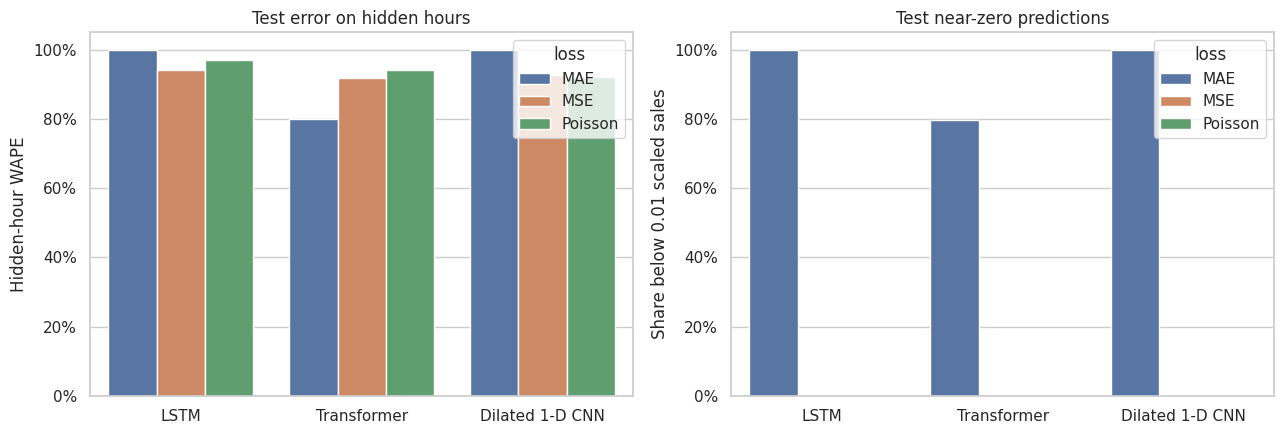

In [11]:
def collect_predictions(model, loader):
    model.eval(); predictions=[]; targets=[]; masks=[]
    with torch.no_grad():
        for xb,yb,mb in loader:
            predictions.append(model(xb.to(DEVICE)).cpu().numpy())
            targets.append(yb.numpy()); masks.append(mb.numpy())
    return np.concatenate(predictions),np.concatenate(targets),np.concatenate(masks)

# Primary scores are on individual hidden hours, matching the project metric definition.
def recovery_scores(pred,target,mask):
    hidden=mask.astype(bool); p=pred[hidden]; y=target[hidden]
    gap_actual=(target*mask).sum(axis=(1,2)); gap_pred=(pred*mask).sum(axis=(1,2))
    return {'hidden_hour_WAPE':np.abs(p-y).sum()/y.sum(),
            'hidden_hour_MAE':np.abs(p-y).mean(),
            'bias':(p-y).sum()/y.sum(),
            'gap_total_WAPE':np.abs(gap_pred-gap_actual).sum()/gap_actual.sum(),
            'mean_prediction':p.mean(),'mean_actual':y.mean(),
            'near_zero_share':(p<.01).mean(),'hidden_hours':len(y)}
rows=[]; product_rows=[]
for (model_name,loss_name),model in trained.items():
    for split in ['valid','test']:
        pred,target,mask=collect_predictions(model,loaders[split])
        rows.append({'model':model_name,'loss':loss_name,'set':split,**recovery_scores(pred,target,mask)})
        if split=='test':
            idx=indices[split]
            for sid,positions in days.iloc[idx].reset_index(drop=True).groupby('series_id').indices.items():
                pos=np.asarray(positions)
                if (target[pos]*mask[pos]).sum()>0:
                    product_rows.append({'series_id':sid,'model':model_name,'loss':loss_name,**recovery_scores(pred[pos],target[pos],mask[pos])})
gap_results=pd.DataFrame(rows)
product_results=pd.DataFrame(product_rows)
print('Validation results (used to compare model/loss configurations):')
display(gap_results[gap_results['set'].eq('valid')].sort_values('hidden_hour_WAPE').round(4))
print('Final test results (Jun 26-Jul 2; no tuning on this week):')
display(gap_results[gap_results['set'].eq('test')].sort_values('hidden_hour_WAPE').round(4))
print('Test WAPE distribution across products with nonzero hidden demand:')
display(product_results.groupby(['model','loss'])['hidden_hour_WAPE'].quantile([.1,.5,.9]).unstack().round(4))
# Pick on validation: among configurations with |bias| <= 10%, lowest gap-total WAPE.
# Hidden-hour WAPE alone rewards predicting too low (most hours sell nothing), so it is not used to select.
val = gap_results[gap_results['set'].eq('valid')]
selected = val[val['bias'].abs().le(0.10)].sort_values('gap_total_WAPE').iloc[0]
chosen=gap_results[(gap_results['set'].eq('test'))&gap_results['model'].eq(selected['model'])&gap_results['loss'].eq(selected['loss'])].iloc[0]
print(f'Validation-selected configuration: {selected["model"]} / {selected["loss"]}. Test hidden-hour WAPE: {chosen["hidden_hour_WAPE"]:.1%}; bias: {chosen["bias"]:+.1%}.')
print('Poisson is used as a mean loss for nonnegative scaled sales, not as a claim that sales are integer Poisson counts.')
print('Synthetic gaps on fully stocked days do not establish accuracy on real stockout demand. Old random-split gap-total scores are superseded and not directly comparable.')
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
te=gap_results[gap_results['set'].eq('test')]
sns.barplot(data=te,x='model',y='hidden_hour_WAPE',hue='loss',ax=axes[0])
sns.barplot(data=te,x='model',y='near_zero_share',hue='loss',ax=axes[1])
axes[0].set(title='Test error on hidden hours',xlabel='',ylabel='Hidden-hour WAPE')
axes[1].set(title='Test near-zero predictions',xlabel='',ylabel='Share below 0.01 scaled sales')
for ax in axes: ax.yaxis.set_major_formatter(lambda x,pos:f'{x:.0%}')
plt.tight_layout(); plt.show()


## Stream 1 findings and handoff
Daily zero-sales detection misses **80.9%** of hourly estimated lost demand because it occurs on days that still record sales. This uses one consistent definition overall, by category, by frozen stockout band, and in the day-adjusted sensitivity. The separate daily-estimate shortfall was previously mislabeled as the headline; that older 78.3% figure is superseded. The matching day-adjusted baseline changes the headline by approximately **-0.10 percentage points**.

The revised gap test uses the frozen training, validation and test dates. Validation selects checkpoints; all configurations share the same masks, initial weights and training budget. Test scores cover 33,189 hidden hours on fully stocked product-days. MSE and Poisson remove the observed collapse: their shares below 0.01 round to 0.0%, versus 79.8% for transformer MAE and 100% for LSTM/CNN MAE.

The loss changes involve a tradeoff. MAE gives the lowest hidden-hour WAPE (transformer MAE: 80.1% on test) but predicts far too low (bias -60.6%), because most hours sell nothing and absolute error rewards predicting near zero. Missed demand is added up into daily totals, so a filler must get the average right, not the typical hour. We therefore select on validation among configurations with bias within ±10%, by lowest gap-total WAPE: dilated 1-D CNN with Poisson loss (test gap-total WAPE 53.7%, bias -10.2%). MSE and Poisson perform similarly across all three networks. These scores use a different masking protocol from the 62% v1 benchmark, so they are not directly comparable, and v1 remains the shared file for forecasting and simulation.

Stream 1 hands off descriptive headline tables and charts. Existing daily_demand_v1.parquet and hourly_demand_v1.parquet remain the shared benchmark for forecasting and simulation; this sensitivity experiment does not replace those files. Gap filling reconstructs a past day from its visible hours; Streams 2 and 4 forecast seven days ahead.

Limitations: one training seed, six epochs, a capped 30,000-day training sample, synthetic blocks on fully stocked days, and unknown demand during actual stockouts. Across-product distributions are reported rather than treating the overall average as universal. Sales are scaled quantities, not physical units or dollars. Networks are trained from scratch with PyTorch; the setup and corrected data come from the team's shared notebooks. This notebook was developed with AI assistance and reviewed against the project plan and available stream conventions.